# Etapa 5: valores de referencia para tinea corporis

Toma `descriptores_texturales.csv` (GLCM) y `descriptores_lbp.csv` (LBP) de la Etapa 5 y construye:

1. Tabla de features por imagen (una fila por imagen), incluyendo **features relativas entre regiones**.
2. Estadística descriptiva y chequeo de redundancia.
3. Rangos de referencia robustos (mediana ± k·MAD) y un score de compatibilidad.
4. Validación **leave-one-out** y sensibilidad de los umbrales.
5. (Opcional) Análisis con negativos si conseguís imágenes de otras patologías.
6. Exportación de `referencia_tinea.json` para usar desde la interfaz gráfica.

Con n pequeño, todo lo que sale de acá es **exploratorio**: los intervalos y la validación LOO están para mostrar cuánta incertidumbre hay.

In [17]:
import sys
sys.path.append("etapas")   # ajustá a la carpeta donde están e5_descriptores.py y e5_lbp.py

import e5_descriptores, e5_lbp

df_glcm = e5_descriptores.procesar_todos_npz()
df_lbp = e5_lbp.procesar_todos_npz()

print(df_glcm.groupby("zona").size())
print(df_lbp["imagen"].unique())

Procesando: e4_roi_EN_01.npz
Procesando: e4_roi_EN_02.npz
Procesando: e4_roi_GA_01.npz
Procesando: e4_roi_GA_02.npz
Procesando: e4_roi_TC_01_PMC.npz
Procesando: e4_roi_TC_02_dermnet.npz
Procesando: e4_roi_TC_03_GSA.npz
Procesando: e4_roi_TC_04_GSA.npz
Procesando: e4_roi_TC_05_dermnet.npz
Procesando: e4_roi_TC_06_ medico.npz
Procesando: e4_roi_TC_07_medico.npz
Procesando: e4_roi_TC_08_wmc.npz
Procesando: e4_roi_TC_09_medico.npz
Procesando: e4_roi_TC_10_MM.npz

Procesamiento terminado.
Resultados guardados en: ..\resultados\Etapa_5\descriptores_texturales.csv
Imágenes procesadas: 14
Registros generados: 56
Archivo guardado en: ..\resultados\Etapa_5\descriptores_lbp.csv
zona
borde           14
centro          14
lesion          14
perilesional    14
dtype: int64
<StringArray>
[        'roi_EN_01',         'roi_EN_02',         'roi_GA_01',
         'roi_GA_02',     'roi_TC_01_PMC', 'roi_TC_02_dermnet',
     'roi_TC_03_GSA',     'roi_TC_04_GSA', 'roi_TC_05_dermnet',
 'roi_TC_06_ medico',  '

In [18]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

RUTA = Path("../resultados/Etapa_5")      # carpeta con los CSV de la Etapa 5
RUTA_ETIQUETAS = None                     # opcional: CSV con columnas imagen,clase (ej. "tinea", "eccema")
K_MAD = 2.5                               # ancho del rango de referencia (en MAD robustos)
RNG = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 110})

## 1. Carga y fusión de los dos CSV

In [19]:
glcm = pd.read_csv(RUTA / "descriptores_texturales.csv").rename(
    columns={"n_pixeles": "n_pix_glcm", "estado": "estado_glcm"})
lbp = pd.read_csv(RUTA / "descriptores_lbp.csv").rename(
    columns={"n_pixeles": "n_pix_lbp", "estado": "estado_lbp"})

largo = glcm.merge(lbp, on=["imagen", "zona"], how="outer")

malos = largo[(largo.estado_glcm != "OK") | (largo.estado_lbp != "OK")]
if len(malos):
    print("Registros excluidos (región insuficiente en GLCM o LBP):")
    display(malos[["imagen", "zona", "estado_glcm", "estado_lbp"]])

largo = largo[(largo.estado_glcm == "OK") & (largo.estado_lbp == "OK")].copy()

# Resumen de LBP uniforme (P=8): códigos 0-8 = patrones uniformes, 9 = no uniforme
largo["lbp_no_uniforme"] = largo["lbp_9"]
largo["lbp_plano_extremo"] = largo["lbp_0"] + largo["lbp_8"]   # centro máximo/mínimo local o plano

print(largo.groupby("zona").size())

zona
borde           14
centro          14
lesion          14
perilesional    14
dtype: int64


## 2. Tabla de features por imagen

Además de los valores absolutos por zona, se calculan **diferencias y log-razones entre regiones**
(`borde−centro`, `borde−perilesional`, `centro−perilesional`). La firma clínica de la tinea (borde activo, aclaramiento central)
es una relación entre regiones, y esas relaciones son más robustas a la iluminación y la cámara que los valores absolutos.

`construir_features` está definida como función para que la interfaz pueda reutilizarla con una sola imagen.

In [20]:
METRICAS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "entropy",
            "lbp_entropia", "lbp_no_uniforme", "lbp_plano_extremo"]
POSITIVAS = ["contrast", "dissimilarity", "entropy", "lbp_entropia"]   # admiten log-razón
PARES = {"borde_centro": ("borde", "centro"),
         "borde_peri": ("borde", "perilesional"),
         "centro_peri": ("centro", "perilesional")}
EPS = 1e-9

def construir_features(df_largo):
    ancho = df_largo.pivot(index="imagen", columns="zona", values=METRICAS)
    ancho.columns = [f"abs_{z}__{m}" for m, z in ancho.columns]
    rel = {}
    for nombre, (a, b) in PARES.items():
        for m in METRICAS:
            va, vb = ancho[f"abs_{a}__{m}"], ancho[f"abs_{b}__{m}"]
            rel[f"dif_{nombre}__{m}"] = va - vb
            if m in POSITIVAS:
                rel[f"lr_{nombre}__{m}"] = np.log((va + EPS) / (vb + EPS))
    return ancho.join(pd.DataFrame(rel))

X = construir_features(largo)
REL = [c for c in X.columns if c.startswith(("dif_", "lr_"))]
print(X.shape, "-> imágenes x features")
X.head()

(14, 75) -> imágenes x features


,abs_borde__contrast,abs_centro__contrast,abs_lesion__contrast,abs_perilesional__contrast,abs_borde__dissimilarity,abs_centro__dissimilarity,abs_lesion__dissimilarity,abs_perilesional__dissimilarity,abs_borde__homogeneity,abs_centro__homogeneity,...,lr_centro_peri__dissimilarity,dif_centro_peri__homogeneity,dif_centro_peri__energy,dif_centro_peri__correlation,dif_centro_peri__entropy,lr_centro_peri__entropy,dif_centro_peri__lbp_entropia,lr_centro_peri__lbp_entropia,dif_centro_peri__lbp_no_uniforme,dif_centro_peri__lbp_plano_extremo
imagen,,,,,,,,,,,,,,,,,,,,,
roi_EN_01,0.555034,0.669392,0.606073,0.237093,0.385230,0.440209,0.409947,0.213485,0.823721,0.801495,...,0.723684,-0.094106,0.009454,-0.050846,0.140509,0.029479,0.066062,0.021191,0.015109,0.008055
roi_EN_02,0.516882,0.558097,0.534137,0.396829,0.368748,0.380660,0.374134,0.301389,0.829788,0.826496,...,0.233506,-0.032123,0.045246,-0.038016,-0.191257,-0.042274,-0.018955,-0.006055,-0.002180,-0.009987
roi_GA_01,0.198506,0.153509,0.180712,0.187942,0.186442,0.148867,0.171593,0.179774,0.907981,0.926030,...,-0.188648,0.015100,0.141622,-0.037392,-1.255223,-0.334297,0.054702,0.017545,0.026789,0.025388
roi_GA_02,0.175610,0.197701,0.184715,0.136642,0.172002,0.194833,0.181409,0.135849,0.914360,0.902870,...,0.360601,-0.029285,0.010597,-0.026666,-0.170637,-0.045483,0.121720,0.041901,0.020545,-0.012063
roi_TC_01_PMC,0.570048,0.365800,0.476355,0.284859,0.432013,0.320265,0.380808,0.266647,0.797235,0.844231,...,0.183221,-0.024251,0.090411,-0.053128,-0.860775,-0.191482,0.043030,0.013500,0.029737,0.019909


In [21]:
# Separar tinea del resto (si hay etiquetas); sin etiquetas, todo se considera tinea
if RUTA_ETIQUETAS:
    etiquetas = pd.read_csv(RUTA_ETIQUETAS).set_index("imagen")["clase"]
    X = X.join(etiquetas, how="left")
    X["clase"] = X["clase"].fillna("sin_etiqueta")
    Xt = X[X["clase"] == "tinea"].drop(columns="clase")
    Xn = X[~X["clase"].isin(["tinea", "sin_etiqueta"])].drop(columns="clase")
    X = X.drop(columns="clase")
else:
    Xt, Xn = X.copy(), X.iloc[0:0]
print(f"Imágenes de tinea: {len(Xt)} | negativos: {len(Xn)}")

Imágenes de tinea: 14 | negativos: 0


## 3. Estadística descriptiva

In [22]:
def descriptiva(df):
    q1, q3 = df.quantile(.25), df.quantile(.75)
    return pd.DataFrame({
        "n": df.count(), "media": df.mean(), "std": df.std(),
        "mediana": df.median(), "IQR": q3 - q1,
        "MAD": df.apply(lambda s: stats.median_abs_deviation(s.dropna(), scale="normal")),
        "min": df.min(), "max": df.max()})

desc = descriptiva(Xt)
desc.loc[[c for c in desc.index if c.startswith("abs_")]].round(4)

,n,media,std,mediana,IQR,MAD,min,max
abs_borde__contrast,14,1.0731,1.8971,0.5625,0.4392,0.3874,0.1155,7.5306
abs_centro__contrast,14,0.9682,1.7540,0.5488,0.5309,0.4497,0.0705,6.9842
abs_lesion__contrast,14,1.0232,1.8244,0.5497,0.4496,0.3701,0.0953,7.2642
abs_perilesional__contrast,14,0.7956,1.5072,0.3249,0.3992,0.2410,0.0857,5.9174
abs_borde__dissimilarity,14,0.5186,0.4865,0.3955,0.2553,0.2215,0.1128,2.0569
abs_centro__dissimilarity,14,0.4930,0.4669,0.3911,0.3105,0.2504,0.0702,1.9879
abs_lesion__dissimilarity,14,0.5061,0.4747,0.3922,0.2715,0.2197,0.0936,2.0229
abs_perilesional__dissimilarity,14,0.4158,0.4410,0.2840,0.2623,0.1638,0.0856,1.8208
abs_borde__homogeneity,14,0.7858,0.1431,0.8190,0.1133,0.0997,0.3846,0.9439
abs_centro__homogeneity,14,0.7925,0.1411,0.8196,0.1352,0.1125,0.3919,0.9649


In [23]:
def tabla_relativas(df, feats):
    filas = []
    for f in feats:
        v = df[f].dropna()
        pos = (v > 0).mean()
        try:
            p = stats.wilcoxon(v).pvalue
        except ValueError:
            p = np.nan
        mad = stats.median_abs_deviation(v, scale="normal")
        filas.append({"feature": f, "mediana": v.median(),
                      "signo_consistente": max(pos, 1 - pos),
                      "signo": "+" if pos >= .5 else "−",
                      "p_wilcoxon_vs_0": p,
                      "cv_robusto": mad / abs(v.median()) if v.median() != 0 else np.nan})
    return pd.DataFrame(filas).set_index("feature")

tabla = tabla_relativas(Xt, REL).sort_values(["signo_consistente", "cv_robusto"], ascending=[False, True])
print("Con n=10, el p mínimo posible del Wilcoxon es ~0.002: un 10/10 de signo consistente es lo mejor que se puede ver.")
tabla.head(15).round(4)

Con n=10, el p mínimo posible del Wilcoxon es ~0.002: un 10/10 de signo consistente es lo mejor que se puede ver.


,mediana,signo_consistente,signo,p_wilcoxon_vs_0,cv_robusto
feature,,,,,
dif_borde_peri__homogeneity,-0.0392,1.0000,−,0.0001,0.4169
lr_borde_peri__contrast,0.3120,1.0000,+,0.0001,0.4485
lr_borde_peri__dissimilarity,0.2324,1.0000,+,0.0001,0.5697
dif_borde_peri__contrast,0.2252,1.0000,+,0.0001,0.6515
dif_borde_peri__dissimilarity,0.1065,1.0000,+,0.0001,0.6760
dif_centro_peri__correlation,-0.0503,0.9286,−,0.0002,0.3714
dif_borde_centro__correlation,0.0273,0.9286,+,0.0006,0.4226
dif_borde_centro__entropy,0.6848,0.9286,+,0.0012,0.5562
lr_borde_centro__entropy,0.1597,0.9286,+,0.0012,0.9405


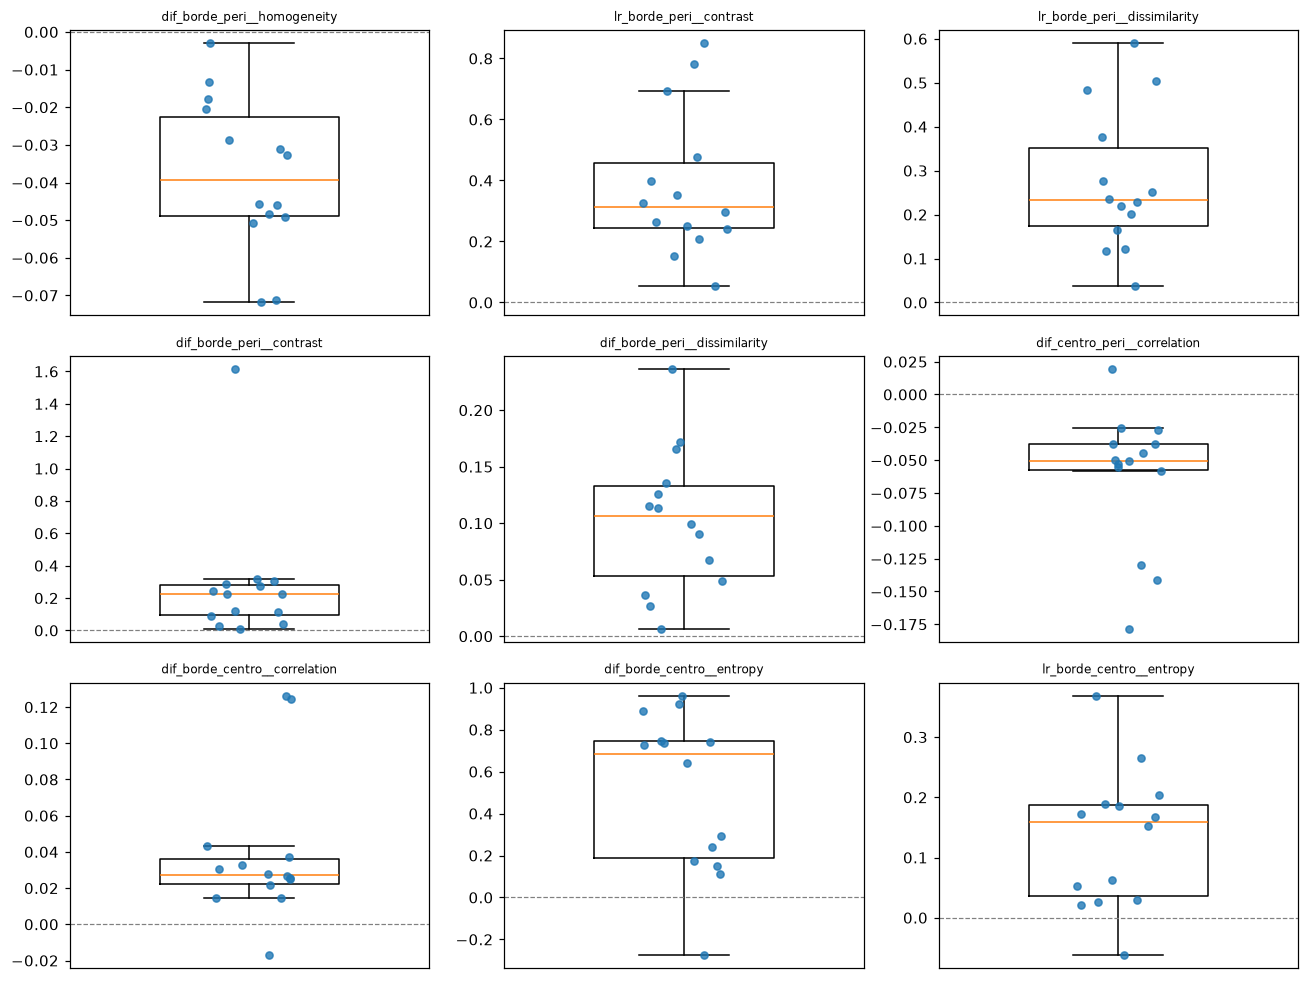

In [24]:
def stripbox(df, feats, ncols=3):
    n = len(feats); nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)
    for ax, f in zip(axs.ravel(), feats):
        v = df[f].dropna().values
        ax.boxplot(v, widths=.5, showfliers=False)
        ax.scatter(1 + RNG.uniform(-.12, .12, len(v)), v, s=22, alpha=.8, zorder=3)
        ax.set_title(f, fontsize=8); ax.set_xticks([])
        if f.startswith(("dif_", "lr_")):
            ax.axhline(0, ls="--", lw=.8, c="gray")
    for ax in axs.ravel()[n:]:
        ax.axis("off")
    fig.tight_layout(); plt.show()

stripbox(Xt, list(tabla.index[:9]))

## 4. Redundancia entre features

Las métricas GLCM están muy correlacionadas entre sí (contrast/dissimilarity, energy/homogeneity/entropy).
Con n pequeño conviene quedarse con **3 a 5 features** poco redundantes.

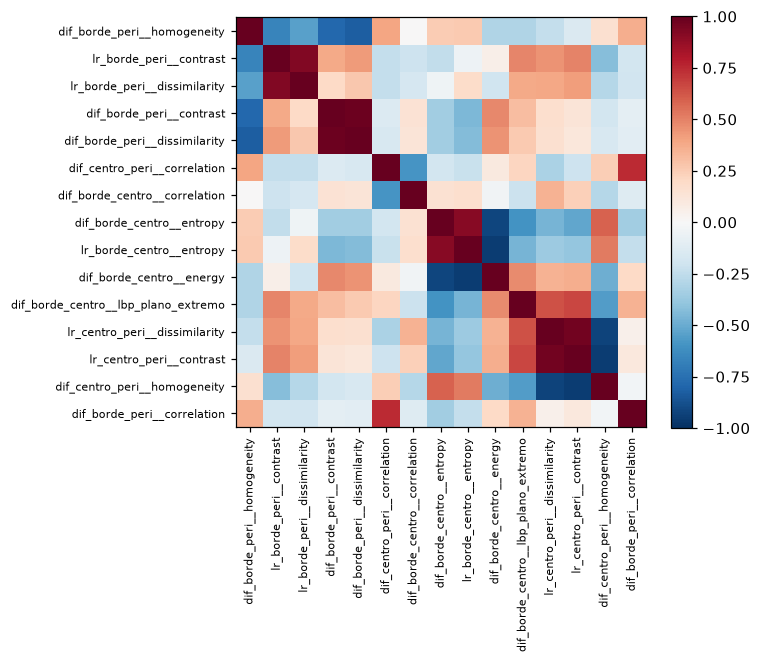

Pares con |rho|>0.9 (elegir uno de cada par):
  lr_borde_peri__contrast  ~  lr_borde_peri__dissimilarity   rho=0.93
  dif_borde_peri__contrast  ~  dif_borde_peri__dissimilarity   rho=0.98
  dif_borde_centro__entropy  ~  lr_borde_centro__entropy   rho=0.91
  dif_borde_centro__entropy  ~  dif_borde_centro__energy   rho=-0.92
  lr_borde_centro__entropy  ~  dif_borde_centro__energy   rho=-0.95
  lr_centro_peri__dissimilarity  ~  lr_centro_peri__contrast   rho=0.96
  lr_centro_peri__dissimilarity  ~  dif_centro_peri__homogeneity   rho=-0.93
  lr_centro_peri__contrast  ~  dif_centro_peri__homogeneity   rho=-0.95


In [25]:
cand = list(tabla.index[:15])
rho = Xt[cand].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(rho, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(cand))); ax.set_xticklabels(cand, rotation=90, fontsize=7)
ax.set_yticks(range(len(cand))); ax.set_yticklabels(cand, fontsize=7)
plt.colorbar(im); plt.tight_layout(); plt.show()

pares = [(a, b, rho.loc[a, b]) for i, a in enumerate(cand) for b in cand[i + 1:] if abs(rho.loc[a, b]) > .9]
print("Pares con |rho|>0.9 (elegir uno de cada par):")
for a, b, r in pares:
    print(f"  {a}  ~  {b}   rho={r:.2f}")

## 5. Rangos de referencia y score de compatibilidad

**Editá `FEATURES_REGLA` después de mirar las secciones 3 y 4.** Los valores por defecto son un punto de partida
(un contraste mayor en el borde que en el centro, y una textura distinta del borde respecto de la piel perilesional).
Criterios sugeridos: signo consistente, bajo CV robusto, poca redundancia, y que tengan sentido clínico.

In [26]:
FEATURES_REGLA = [
    "dif_borde_centro__contrast",
    "dif_borde_peri__homogeneity",
    "dif_borde_peri__energy",
    "dif_borde_centro__lbp_entropia",
]
faltan = [f for f in FEATURES_REGLA if f not in Xt.columns]
assert not faltan, f"Features inexistentes: {faltan}"

def referencia(df, feats, k=K_MAD):
    med = df[feats].median()
    mad = df[feats].apply(lambda s: stats.median_abs_deviation(s.dropna(), scale="normal"))
    mad = mad.where(mad > 0, df[feats].std())          # si MAD=0, usar el desvío
    return pd.DataFrame({"mediana": med, "mad": mad, "lo": med - k * mad, "hi": med + k * mad})

def evaluar(x, ref, k=K_MAD):
    z = (x[ref.index] - ref["mediana"]) / ref["mad"]
    dentro = z.abs() <= k
    return {"frac_dentro": dentro.mean(), "n_fuera": int((~dentro).sum()),
            "z_abs_medio": z.abs().mean()}, z

ref = referencia(Xt, FEATURES_REGLA)
ref.round(4)

,mediana,mad,lo,hi
dif_borde_centro__contrast,0.0450,0.1136,-0.2391,0.3291
dif_borde_peri__homogeneity,-0.0392,0.0163,-0.0801,0.0017
dif_borde_peri__energy,-0.0014,0.0323,-0.0823,0.0795
dif_borde_centro__lbp_entropia,-0.0037,0.0329,-0.0859,0.0786


In [27]:
# Incertidumbre de la mediana por bootstrap
def boot_ci(serie, B=5000, alpha=.05):
    v = serie.dropna().values
    meds = np.median(v[RNG.integers(0, len(v), (B, len(v)))], axis=1)
    return np.quantile(meds, [alpha / 2, 1 - alpha / 2])

ci = pd.DataFrame({f: boot_ci(Xt[f]) for f in FEATURES_REGLA}, index=["ic95_lo", "ic95_hi"]).T
ref.join(ci).round(4)

,mediana,mad,lo,hi,ic95_lo,ic95_hi
dif_borde_centro__contrast,0.0450,0.1136,-0.2391,0.3291,-0.0221,0.2042
dif_borde_peri__homogeneity,-0.0392,0.0163,-0.0801,0.0017,-0.0491,-0.0233
dif_borde_peri__energy,-0.0014,0.0323,-0.0823,0.0795,-0.0200,0.0192
dif_borde_centro__lbp_entropia,-0.0037,0.0329,-0.0859,0.0786,-0.0101,0.0436


## 6. Validación leave-one-out y sensibilidad

Cada imagen se evalúa contra una referencia calculada **sin ella**. El resultado “en muestra” (referencia con todas)
se muestra solo para comparar: siempre es más optimista.

In [28]:
def loo(df, feats):
    filas = []
    for img in df.index:
        tr = df.drop(img)
        r = referencia(tr, feats)
        res, z = evaluar(df.loc[img], r)
        res.update(imagen=img, feature_peor=z.abs().idxmax())
        filas.append(res)
    return pd.DataFrame(filas).set_index("imagen")

res_loo = loo(Xt, FEATURES_REGLA)
res_in = pd.DataFrame([evaluar(Xt.loc[i], ref)[0] for i in Xt.index], index=Xt.index)

display(res_loo.round(3))

print("Tasa de aceptación de la tinea según umbral de 'frac_dentro':")
tasa = pd.DataFrame({
    "umbral": [0.5, 0.67, 0.75, 1.0],
}).assign(
    en_muestra=lambda d: [(res_in.frac_dentro >= t).mean() for t in d.umbral],
    loo=lambda d: [(res_loo.frac_dentro >= t).mean() for t in d.umbral])
tasa

,frac_dentro,n_fuera,z_abs_medio,feature_peor
imagen,,,,
roi_EN_01,1.00,0,0.901,dif_borde_peri__homogeneity
roi_EN_02,1.00,0,0.719,dif_borde_centro__lbp_entropia
roi_GA_01,1.00,0,1.206,dif_borde_peri__homogeneity
roi_GA_02,0.75,1,1.945,dif_borde_centro__lbp_entropia
roi_TC_01_PMC,1.00,0,1.025,dif_borde_peri__homogeneity
roi_TC_02_dermnet,1.00,0,0.970,dif_borde_centro__contrast
roi_TC_03_GSA,0.75,1,1.472,dif_borde_centro__lbp_entropia
roi_TC_04_GSA,1.00,0,0.710,dif_borde_peri__energy
roi_TC_05_dermnet,0.75,1,2.425,dif_borde_centro__contrast


Tasa de aceptación de la tinea según umbral de 'frac_dentro':


,umbral,en_muestra,loo
0,0.50,1.000000,1.000000
1,0.67,1.000000,1.000000
2,0.75,1.000000,1.000000
3,1.00,0.571429,0.571429


,lo,hi,lo_min,lo_max,hi_min,hi_max,variacion_rel_ancho
dif_borde_centro__contrast,-0.2391,0.3291,-0.2745,-0.2037,0.2937,0.3645,0.1247
dif_borde_peri__homogeneity,-0.0801,0.0017,-0.1081,-0.0881,0.0084,0.0248,0.6269
dif_borde_peri__energy,-0.0823,0.0795,-0.1033,-0.0714,0.0644,0.0963,0.2339
dif_borde_centro__lbp_entropia,-0.0859,0.0786,-0.1089,-0.0629,0.0584,0.0988,0.2628


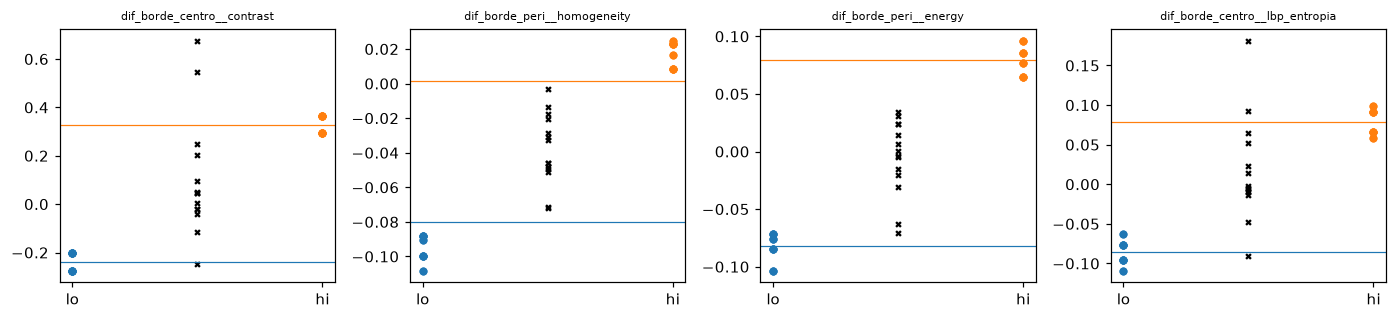

In [29]:
# Sensibilidad de los límites al sacar una imagen
filas = []
for img in Xt.index:
    r = referencia(Xt.drop(img), FEATURES_REGLA)
    filas.append(r[["lo", "hi"]].assign(sin=img, feature=r.index))
sens = pd.concat(filas)

resumen = sens.groupby("feature").agg(lo_min=("lo", "min"), lo_max=("lo", "max"),
                                       hi_min=("hi", "min"), hi_max=("hi", "max"))
resumen = ref[["lo", "hi"]].join(resumen)
resumen["variacion_rel_ancho"] = ((resumen.hi_max - resumen.lo_min) - (resumen.hi - resumen.lo)) / (resumen.hi - resumen.lo)
display(resumen.round(4))

fig, axs = plt.subplots(1, len(FEATURES_REGLA), figsize=(3.2 * len(FEATURES_REGLA), 3), squeeze=False)
for ax, f in zip(axs.ravel(), FEATURES_REGLA):
    s = sens[sens.feature == f]
    ax.scatter(np.zeros(len(s)), s.lo, s=18, label="lo (sin una img)")
    ax.scatter(np.ones(len(s)), s.hi, s=18, label="hi (sin una img)")
    ax.axhline(ref.loc[f, "lo"], c="C0", lw=.8); ax.axhline(ref.loc[f, "hi"], c="C1", lw=.8)
    ax.scatter(np.full(len(Xt), .5), Xt[f], c="k", s=10, marker="x")
    ax.set_title(f, fontsize=7); ax.set_xticks([0, 1]); ax.set_xticklabels(["lo", "hi"])
plt.tight_layout(); plt.show()

## 7. (Opcional) Con negativos

Si completás `RUTA_ETIQUETAS` con un CSV `imagen,clase` (clase = `tinea`, `eccema`, `psoriasis`, …) y procesaste esas
imágenes por **el mismo pipeline** (Etapas 4 y 5), esta sección:

- evalúa los negativos contra la referencia hecha **solo con tinea**,
- calcula AUC (Mann-Whitney) y d de Cohen por feature,
- compara las tasas de aceptación de tinea y de negativos para cada umbral de la regla.

Sin negativos, se omite.

In [30]:
if len(Xn) == 0:
    print("Sin negativos: sección omitida. Interpretar el score como 'compatibilidad con el perfil de tinea', no como diagnóstico.")
else:
    # (a) score de compatibilidad: tinea (LOO) vs negativos (referencia completa)
    sc_neg = pd.DataFrame([evaluar(Xn.loc[i], ref)[0] for i in Xn.index], index=Xn.index)
    u = stats.mannwhitneyu(res_loo.frac_dentro, sc_neg.frac_dentro).statistic
    print(f"AUC del score frac_dentro (tinea LOO vs negativos): {u / (len(res_loo) * len(sc_neg)):.2f}")
    comp = pd.DataFrame({"umbral": [0.5, 0.67, 0.75, 1.0]})
    comp["tinea_aceptada_LOO"] = [(res_loo.frac_dentro >= t).mean() for t in comp.umbral]
    comp["negativos_aceptados"] = [(sc_neg.frac_dentro >= t).mean() for t in comp.umbral]
    display(comp.round(2))

    # (b) AUC univariado (Mann-Whitney) y d de Cohen por feature
    filas = []
    for f in REL:
        a, b = Xt[f].dropna(), Xn[f].dropna()
        u = stats.mannwhitneyu(a, b).statistic
        sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
        filas.append({"feature": f, "auc": u / (len(a) * len(b)),
                      "d_cohen": (a.mean() - b.mean()) / sp if sp > 0 else np.nan})
    uni = pd.DataFrame(filas).set_index("feature")
    uni["auc_max"] = np.maximum(uni.auc, 1 - uni.auc)
    display(uni.sort_values("auc_max", ascending=False).head(10).round(3))

Sin negativos: sección omitida. Interpretar el score como 'compatibilidad con el perfil de tinea', no como diagnóstico.


## 8. Exportar para la interfaz

`referencia_tinea.json` guarda los rangos y la configuración. La interfaz debe: (1) calcular los mismos descriptores
de la ROI con las funciones de la Etapa 5, (2) armar las features con `construir_features` (mover esa función a un módulo
`.py` compartido), (3) llamar a `evaluar_con_referencia`.

In [31]:
UMBRAL_ACEPTACION = 0.75      # ajustar mirando la tabla de tasas de la sección 6

payload = {
    "version": "exploratoria",
    "n_imagenes_referencia": int(len(Xt)),
    "k_mad": K_MAD,
    "umbral_aceptacion": UMBRAL_ACEPTACION,
    "features": {f: {k: float(v) for k, v in ref.loc[f].items()} for f in FEATURES_REGLA},
    "nota": "Valores derivados de un conjunto pequeño y heterogéneo; compatibilidad con perfil de tinea, no diagnóstico.",
}
with open(RUTA / "referencia_tinea.json", "w", encoding="utf-8") as fh:
    json.dump(payload, fh, indent=2, ensure_ascii=False)

def evaluar_con_referencia(features_imagen, ruta_json=RUTA / "referencia_tinea.json"):
    """features_imagen: dict/Series con las features de UNA imagen. Devuelve veredicto y detalle por feature."""
    cfg = json.load(open(ruta_json, encoding="utf-8"))
    detalle = {}
    for f, r in cfg["features"].items():
        z = (features_imagen[f] - r["mediana"]) / r["mad"]
        detalle[f] = {"valor": float(features_imagen[f]), "z": float(z),
                      "dentro": bool(abs(z) <= cfg["k_mad"]), "rango": [r["lo"], r["hi"]]}
    frac = np.mean([d["dentro"] for d in detalle.values()])
    return {"compatible": bool(frac >= cfg["umbral_aceptacion"]), "frac_dentro": float(frac), "detalle": detalle}

# Prueba rápida con una imagen conocida
evaluar_con_referencia(Xt.iloc[0])["compatible"], payload["features"].keys()

(True,
 dict_keys(['dif_borde_centro__contrast', 'dif_borde_peri__homogeneity', 'dif_borde_peri__energy', 'dif_borde_centro__lbp_entropia']))

In [32]:
import pandas as pd

# 1. Cargar el CSV que ya generaste
df_glcm = pd.read_csv("../resultados/Etapa_5/descriptores_texturales.csv")

# 2. Reorganizar por imagen y por zona
piv = df_glcm.pivot(index='imagen', columns='zona', values=['contrast', 'energy', 'entropy', 'homogeneity'])

# 3. Crear los parámetros de decisión intrínsecos de la tiña
df_caracteristicas = pd.DataFrame(index=piv.index)

# A) Gradiente Borde vs. Centro (Refleja el descamado activo del borde vs el centro aclarado)
df_caracteristicas['dif_entropia_borde_centro'] = piv['entropy']['borde'] - piv['entropy']['centro']
df_caracteristicas['ratio_energia_centro_borde'] = piv['energy']['centro'] / piv['energy']['borde']

# B) Gradiente Lesión vs. Piel Sana (Refleja el realce del borde respecto a la piel sana)
df_caracteristicas['ratio_contraste_borde_peri'] = piv['contrast']['borde'] / piv['contrast']['perilesional']

print(df_caracteristicas.head())

               dif_entropia_borde_centro  ratio_energia_centro_borde  \
imagen                                                                 
roi_EN_01                       0.148587                    1.063688   
roi_EN_02                       0.239495                    1.156751   
roi_GA_01                       0.962732                    1.415418   
roi_GA_02                       0.748197                    1.317903   
roi_TC_01_PMC                   0.741860                    1.334403   

               ratio_contraste_borde_peri  
imagen                                     
roi_EN_01                        2.340994  
roi_EN_02                        1.302531  
roi_GA_01                        1.056212  
roi_GA_02                        1.285181  
roi_TC_01_PMC                    2.001161  
